In [22]:
# 한글 깨짐 방지 위해 구글 코랩에 나눔폰트 설치.
import sys
if 'google.colab' in sys.modules:
    !echo 'debconf debconf/frontend select Noninteractive' | debconf-set-selections
    !sudo apt-get -qq -y install fonts-nanum
    import matplotlib.font_manager as fm
    font_files = fm.findSystemFonts(fontpaths=['/usr/share/fonts/truetype/nanum'])
    for fpath in font_files:
        fm.fontManager.addfont(fpath)

In [23]:
# 나눔고딕으로 폰트 변경
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'NanumGothic'

In [24]:
# matplot의 폰트와 폰트 크기 확인
print(plt.rcParams['font.family'], plt.rcParams['font.size'])

['NanumGothic'] 10.0


In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [26]:
default_data = pd.read_csv('모델 정확도(디폴트_fi_pca_pi).csv')
paper_data = pd.read_csv('모델 정확도(논문 기준_fi_pca_pi).csv')
gs_data = pd.read_csv('모델 정확도(그리드서치_fi_pca_pi).csv')

In [27]:
default_data.head()

,모델,default_정확도(교차검증),default_정확도(테스트),default_정확도(fi_교차검증),default_정확도(fi_테스트),default_정확도(pca_교차검증),default_정확도(pca_테스트),default_정확도(pi_교차검증),default_정확도(pi_테스트)
0,RandomForest,0.977215,0.978246,0.979596,0.978246,0.945418,0.946975,0.978576,0.976207
1,LogisticRegression,0.983336,0.980965,0.976535,0.980286,0.983507,0.979606,0.981296,0.983005
2,SVM,0.968203,0.973487,0.968883,0.970768,0.978915,0.983005,0.970073,0.975527
3,DecisionTreeClassifier,0.934877,0.940177,0.935556,0.939497,0.864139,0.864718,0.943887,0.938817


In [28]:
paper_data.head()

,모델,논문_정확도(교차검증),논문_정확도(테스트),논문_정확도(fi_교차검증),논문_정확도(fi_테스트),논문_정확도(pca_교차검증),논문_정확도(pca_테스트),논문_정확도(pi_교차검증),논문_정확도(pi_테스트)
0,RandomForest,0.953920,0.953093,0.954089,0.979606,0.892196,0.879674,0.950859,0.939497
1,LogisticRegression,0.983677,0.980965,0.979595,0.978926,0.982146,0.981645,0.984186,0.986404
2,SVM,0.985037,0.984364,0.979425,0.981645,0.985547,0.984364,0.982826,0.976886
3,DecisionTreeClassifier,0.893045,0.882393,0.892705,0.882393,0.781669,0.767505,0.897465,0.882393


In [29]:
gs_data.head()

,모델,gs_정확도(교차검증),gs_정확도(테스트),gs_정확도(fi_교차검증),gs_정확도(fi_테스트),gs_정확도(pca_교차검증),gs_정확도(pca_테스트),gs_정확도(pi_교차검증),gs_정확도(pi_테스트)
0,RandomForest,0.970243,0.966689,0.970754,0.968049,0.922801,0.915024,0.956300,0.952413
1,LogisticRegression,0.984187,0.982325,0.978745,0.982325,0.984187,0.983005,0.984867,0.980965
2,SVM,0.988438,0.989803,0.987757,0.989803,0.988607,0.993882,0.981296,0.981645
3,DecisionTreeClassifier,0.941849,0.942216,0.942359,0.949694,0.872811,0.883073,0.950521,0.949014


In [30]:
df = default_data.merge(paper_data, left_on=['모델'], right_on=['모델'])
df

,모델,default_정확도(교차검증),default_정확도(테스트),default_정확도(fi_교차검증),default_정확도(fi_테스트),default_정확도(pca_교차검증),default_정확도(pca_테스트),default_정확도(pi_교차검증),default_정확도(pi_테스트),논문_정확도(교차검증),논문_정확도(테스트),논문_정확도(fi_교차검증),논문_정확도(fi_테스트),논문_정확도(pca_교차검증),논문_정확도(pca_테스트),논문_정확도(pi_교차검증),논문_정확도(pi_테스트)
0,RandomForest,0.977215,0.978246,0.979596,0.978246,0.945418,0.946975,0.978576,0.976207,0.953920,0.953093,0.954089,0.979606,0.892196,0.879674,0.950859,0.939497
1,LogisticRegression,0.983336,0.980965,0.976535,0.980286,0.983507,0.979606,0.981296,0.983005,0.983677,0.980965,0.979595,0.978926,0.982146,0.981645,0.984186,0.986404
2,SVM,0.968203,0.973487,0.968883,0.970768,0.978915,0.983005,0.970073,0.975527,0.985037,0.984364,0.979425,0.981645,0.985547,0.984364,0.982826,0.976886
3,DecisionTreeClassifier,0.934877,0.940177,0.935556,0.939497,0.864139,0.864718,0.943887,0.938817,0.893045,0.882393,0.892705,0.882393,0.781669,0.767505,0.897465,0.882393


In [31]:
df = df.merge(gs_data, left_on=['모델'], right_on=['모델'])
df

,모델,default_정확도(교차검증),default_정확도(테스트),default_정확도(fi_교차검증),default_정확도(fi_테스트),default_정확도(pca_교차검증),default_정확도(pca_테스트),default_정확도(pi_교차검증),default_정확도(pi_테스트),논문_정확도(교차검증),...,논문_정확도(pi_교차검증),논문_정확도(pi_테스트),gs_정확도(교차검증),gs_정확도(테스트),gs_정확도(fi_교차검증),gs_정확도(fi_테스트),gs_정확도(pca_교차검증),gs_정확도(pca_테스트),gs_정확도(pi_교차검증),gs_정확도(pi_테스트)
0,RandomForest,0.977215,0.978246,0.979596,0.978246,0.945418,0.946975,0.978576,0.976207,0.953920,...,0.950859,0.939497,0.970243,0.966689,0.970754,0.968049,0.922801,0.915024,0.956300,0.952413
1,LogisticRegression,0.983336,0.980965,0.976535,0.980286,0.983507,0.979606,0.981296,0.983005,0.983677,...,0.984186,0.986404,0.984187,0.982325,0.978745,0.982325,0.984187,0.983005,0.984867,0.980965
2,SVM,0.968203,0.973487,0.968883,0.970768,0.978915,0.983005,0.970073,0.975527,0.985037,...,0.982826,0.976886,0.988438,0.989803,0.987757,0.989803,0.988607,0.993882,0.981296,0.981645
3,DecisionTreeClassifier,0.934877,0.940177,0.935556,0.939497,0.864139,0.864718,0.943887,0.938817,0.893045,...,0.897465,0.882393,0.941849,0.942216,0.942359,0.949694,0.872811,0.883073,0.950521,0.949014


In [32]:
df.to_csv('모델 정확도(종합).csv', index=False, encoding='utf-8-sig')

In [33]:
df

,모델,default_정확도(교차검증),default_정확도(테스트),default_정확도(fi_교차검증),default_정확도(fi_테스트),default_정확도(pca_교차검증),default_정확도(pca_테스트),default_정확도(pi_교차검증),default_정확도(pi_테스트),논문_정확도(교차검증),...,논문_정확도(pi_교차검증),논문_정확도(pi_테스트),gs_정확도(교차검증),gs_정확도(테스트),gs_정확도(fi_교차검증),gs_정확도(fi_테스트),gs_정확도(pca_교차검증),gs_정확도(pca_테스트),gs_정확도(pi_교차검증),gs_정확도(pi_테스트)
0,RandomForest,0.977215,0.978246,0.979596,0.978246,0.945418,0.946975,0.978576,0.976207,0.953920,...,0.950859,0.939497,0.970243,0.966689,0.970754,0.968049,0.922801,0.915024,0.956300,0.952413
1,LogisticRegression,0.983336,0.980965,0.976535,0.980286,0.983507,0.979606,0.981296,0.983005,0.983677,...,0.984186,0.986404,0.984187,0.982325,0.978745,0.982325,0.984187,0.983005,0.984867,0.980965
2,SVM,0.968203,0.973487,0.968883,0.970768,0.978915,0.983005,0.970073,0.975527,0.985037,...,0.982826,0.976886,0.988438,0.989803,0.987757,0.989803,0.988607,0.993882,0.981296,0.981645
3,DecisionTreeClassifier,0.934877,0.940177,0.935556,0.939497,0.864139,0.864718,0.943887,0.938817,0.893045,...,0.897465,0.882393,0.941849,0.942216,0.942359,0.949694,0.872811,0.883073,0.950521,0.949014


In [34]:
df.set_index('모델', inplace=True)

In [35]:
df

,default_정확도(교차검증),default_정확도(테스트),default_정확도(fi_교차검증),default_정확도(fi_테스트),default_정확도(pca_교차검증),default_정확도(pca_테스트),default_정확도(pi_교차검증),default_정확도(pi_테스트),논문_정확도(교차검증),논문_정확도(테스트),...,논문_정확도(pi_교차검증),논문_정확도(pi_테스트),gs_정확도(교차검증),gs_정확도(테스트),gs_정확도(fi_교차검증),gs_정확도(fi_테스트),gs_정확도(pca_교차검증),gs_정확도(pca_테스트),gs_정확도(pi_교차검증),gs_정확도(pi_테스트)
모델,,,,,,,,,,,,,,,,,,,,,
RandomForest,0.977215,0.978246,0.979596,0.978246,0.945418,0.946975,0.978576,0.976207,0.953920,0.953093,...,0.950859,0.939497,0.970243,0.966689,0.970754,0.968049,0.922801,0.915024,0.956300,0.952413
LogisticRegression,0.983336,0.980965,0.976535,0.980286,0.983507,0.979606,0.981296,0.983005,0.983677,0.980965,...,0.984186,0.986404,0.984187,0.982325,0.978745,0.982325,0.984187,0.983005,0.984867,0.980965
SVM,0.968203,0.973487,0.968883,0.970768,0.978915,0.983005,0.970073,0.975527,0.985037,0.984364,...,0.982826,0.976886,0.988438,0.989803,0.987757,0.989803,0.988607,0.993882,0.981296,0.981645
DecisionTreeClassifier,0.934877,0.940177,0.935556,0.939497,0.864139,0.864718,0.943887,0.938817,0.893045,0.882393,...,0.897465,0.882393,0.941849,0.942216,0.942359,0.949694,0.872811,0.883073,0.950521,0.949014


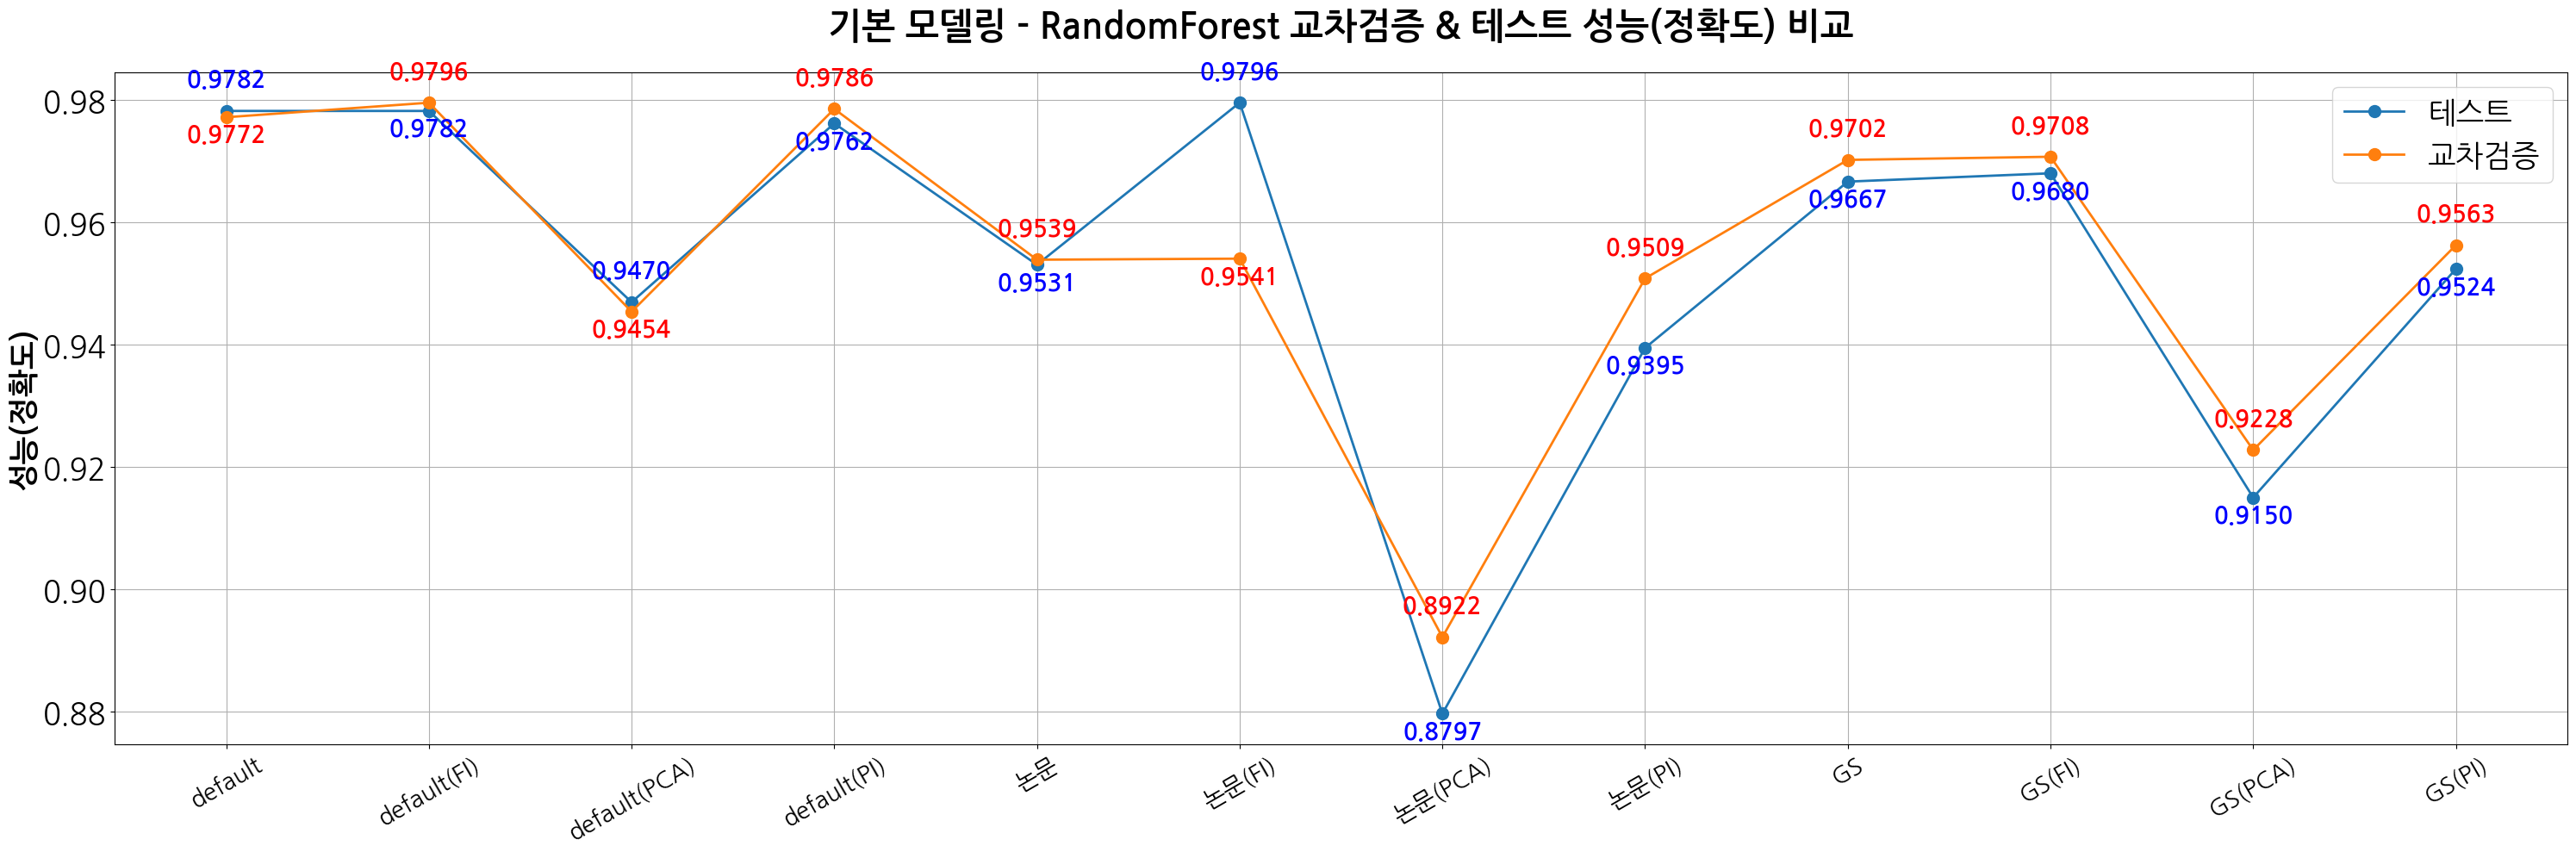

In [36]:
# x축 라벨
x_labels = ['default', 'default(FI)', 'default(PCA)', 'default(PI)',
            '논문', '논문(FI)', '논문(PCA)', '논문(PI)',
            'GS', 'GS(FI)', 'GS(PCA)', 'GS(PI)']

# RandomForest 테스트 및 교차검증 정확도 추출
rf_test = df.loc['RandomForest', [
    'default_정확도(테스트)', 'default_정확도(fi_테스트)', 'default_정확도(pca_테스트)', 'default_정확도(pi_테스트)',
    '논문_정확도(테스트)', '논문_정확도(fi_테스트)', '논문_정확도(pca_테스트)', '논문_정확도(pi_테스트)',
    'gs_정확도(테스트)', 'gs_정확도(fi_테스트)', 'gs_정확도(pca_테스트)', 'gs_정확도(pi_테스트)'
]]

rf_cv = df.loc['RandomForest', [
    'default_정확도(교차검증)', 'default_정확도(fi_교차검증)', 'default_정확도(pca_교차검증)', 'default_정확도(pi_교차검증)',
    '논문_정확도(교차검증)', '논문_정확도(fi_교차검증)', '논문_정확도(pca_교차검증)', '논문_정확도(pi_교차검증)',
    'gs_정확도(교차검증)', 'gs_정확도(fi_교차검증)', 'gs_정확도(pca_교차검증)', 'gs_정확도(pi_교차검증)'
]]

# 그래프 그리기
plt.figure(figsize=(30, 10))
plt.plot(x_labels, rf_test.values, marker='o', markersize=10, linewidth=2, label='테스트')
plt.plot(x_labels, rf_cv.values, marker='o', markersize=10, linewidth=2, label='교차검증')

# 각 지점에서 더 큰 값은 위, 더 작은 값은 아래에 표시
for i, (test_val, cv_val) in enumerate(zip(rf_test.values, rf_cv.values)):
    if test_val >= cv_val:
        plt.text(i, test_val + 0.004, f"{test_val:.4f}", ha='center', fontsize=20, color='blue', fontweight='bold')
        plt.text(i, cv_val - 0.004, f"{cv_val:.4f}", ha='center', fontsize=20, color='red', fontweight='bold')
    else:
        plt.text(i, test_val - 0.004, f"{test_val:.4f}", ha='center', fontsize=20, color='blue', fontweight='bold')
        plt.text(i, cv_val + 0.004, f"{cv_val:.4f}", ha='center', fontsize=20, color='red', fontweight='bold')


# 축, 제목, 범례 설정
plt.xticks(rotation=30, fontsize=20)
plt.yticks(fontsize=25)
plt.ylabel("성능(정확도)", fontsize=25, fontweight='bold')
plt.title("기본 모델링 - RandomForest 교차검증 & 테스트 성능(정확도) 비교", fontsize=30, fontweight='bold', pad=30)
plt.legend(fontsize=25)
plt.grid(True)
plt.tight_layout()
plt.show()

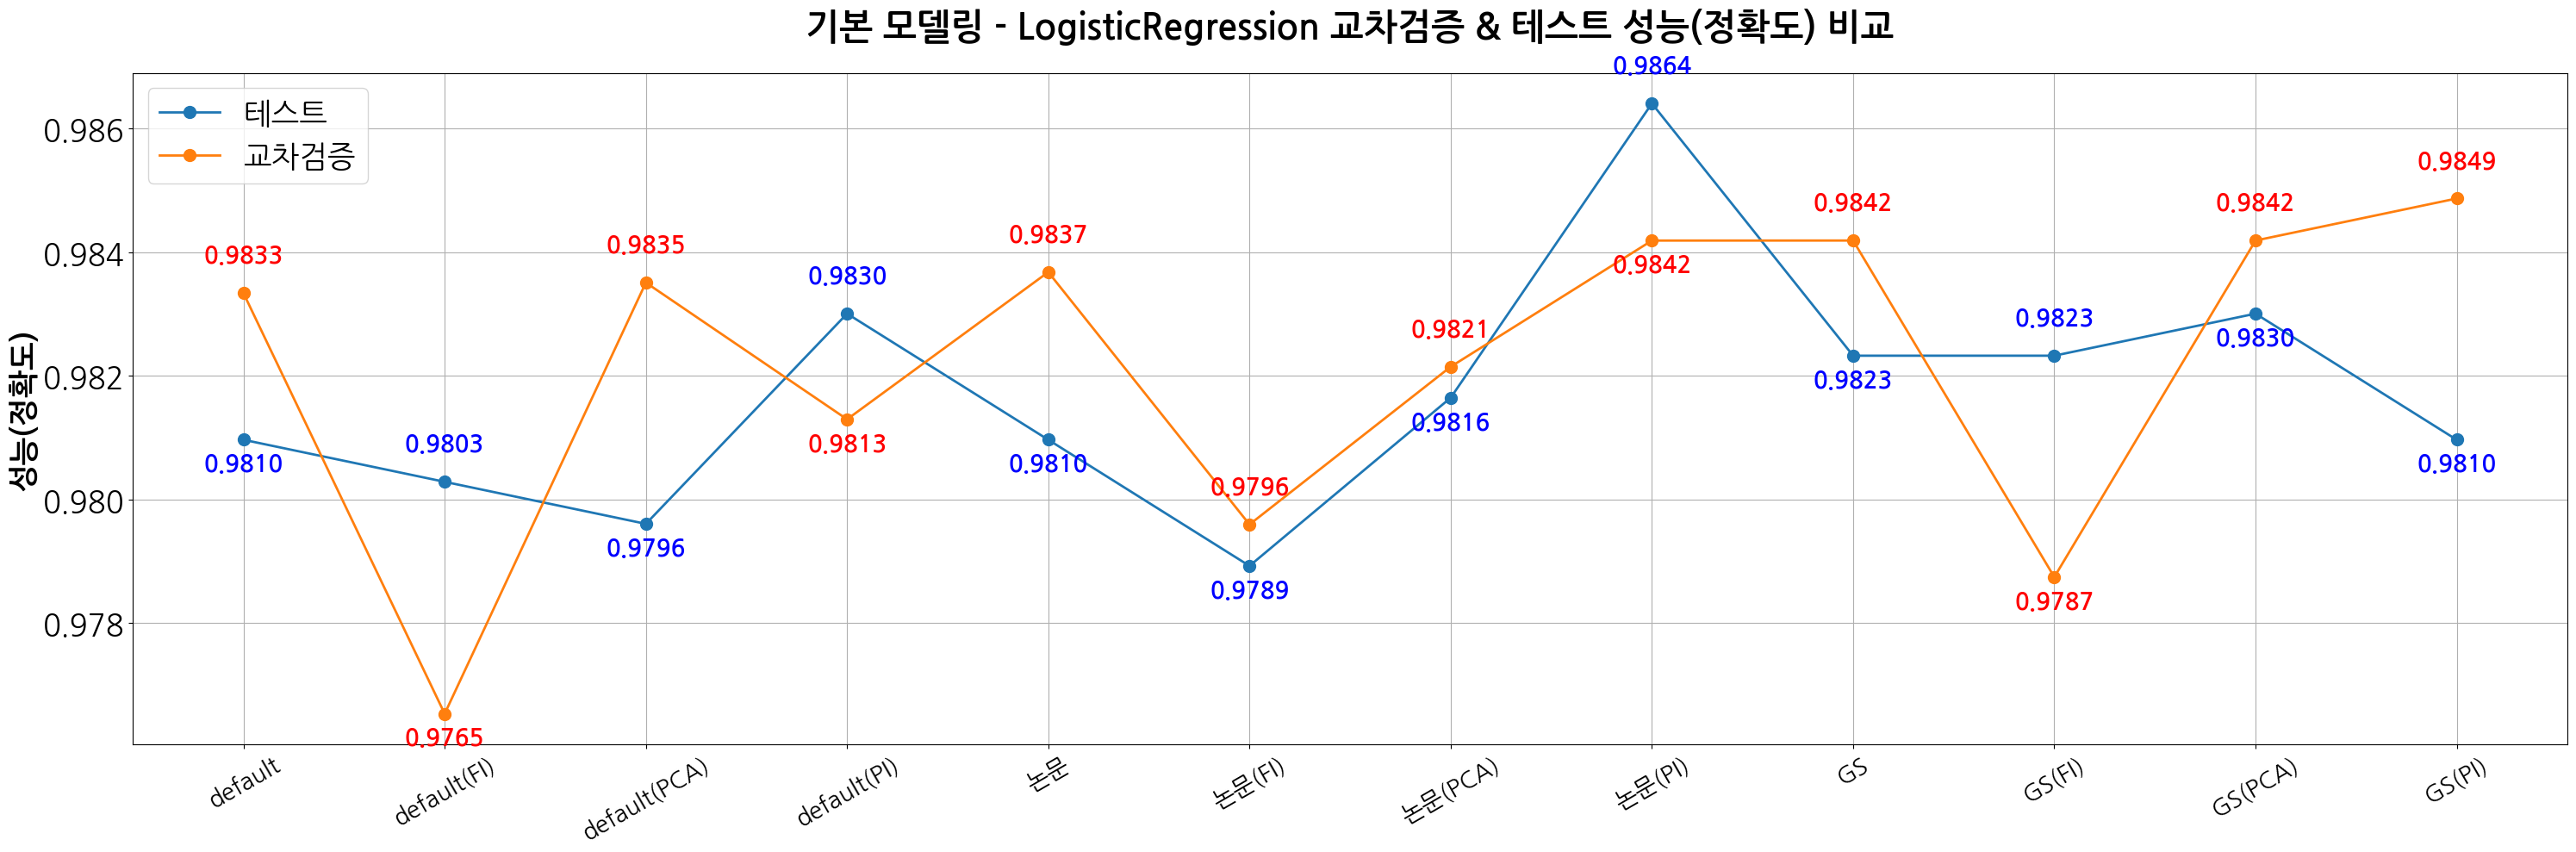

In [37]:
# x축 라벨
x_labels = ['default', 'default(FI)', 'default(PCA)', 'default(PI)',
            '논문', '논문(FI)', '논문(PCA)', '논문(PI)',
            'GS', 'GS(FI)', 'GS(PCA)', 'GS(PI)']

# LogisticRegression 테스트 및 교차검증 정확도 추출
lr_test = df.loc['LogisticRegression', [
    'default_정확도(테스트)', 'default_정확도(fi_테스트)', 'default_정확도(pca_테스트)', 'default_정확도(pi_테스트)',
    '논문_정확도(테스트)', '논문_정확도(fi_테스트)', '논문_정확도(pca_테스트)', '논문_정확도(pi_테스트)',
    'gs_정확도(테스트)', 'gs_정확도(fi_테스트)', 'gs_정확도(pca_테스트)', 'gs_정확도(pi_테스트)'
]]

lr_cv = df.loc['LogisticRegression', [
    'default_정확도(교차검증)', 'default_정확도(fi_교차검증)', 'default_정확도(pca_교차검증)', 'default_정확도(pi_교차검증)',
    '논문_정확도(교차검증)', '논문_정확도(fi_교차검증)', '논문_정확도(pca_교차검증)', '논문_정확도(pi_교차검증)',
    'gs_정확도(교차검증)', 'gs_정확도(fi_교차검증)', 'gs_정확도(pca_교차검증)', 'gs_정확도(pi_교차검증)'
]]

# 그래프 그리기
plt.figure(figsize=(30, 10))
plt.plot(x_labels, lr_test.values, marker='o', markersize=10, linewidth=2, label='테스트')
plt.plot(x_labels, lr_cv.values, marker='o', markersize=10, linewidth=2, label='교차검증')

# 각 지점에서 더 큰 값은 위, 더 작은 값은 아래에 표시
for i, (test_val, cv_val) in enumerate(zip(lr_test.values, lr_cv.values)):
    if test_val >= cv_val:
        plt.text(i, test_val + 0.0005, f"{test_val:.4f}", ha='center', fontsize=20, color='blue', fontweight='bold')
        plt.text(i, cv_val - 0.0005, f"{cv_val:.4f}", ha='center', fontsize=20, color='red', fontweight='bold')
    else:
        plt.text(i, test_val - 0.0005, f"{test_val:.4f}", ha='center', fontsize=20, color='blue', fontweight='bold')
        plt.text(i, cv_val + 0.0005, f"{cv_val:.4f}", ha='center', fontsize=20, color='red', fontweight='bold')


# 축, 제목, 범례 설정
plt.xticks(rotation=30, fontsize=20)
plt.yticks(fontsize=25)
plt.ylabel("성능(정확도)", fontsize=25, fontweight='bold')
plt.title("기본 모델링 - LogisticRegression 교차검증 & 테스트 성능(정확도) 비교", fontsize=30, fontweight='bold', pad=30)
plt.legend(fontsize=25)
plt.grid(True)
plt.tight_layout()
plt.show()

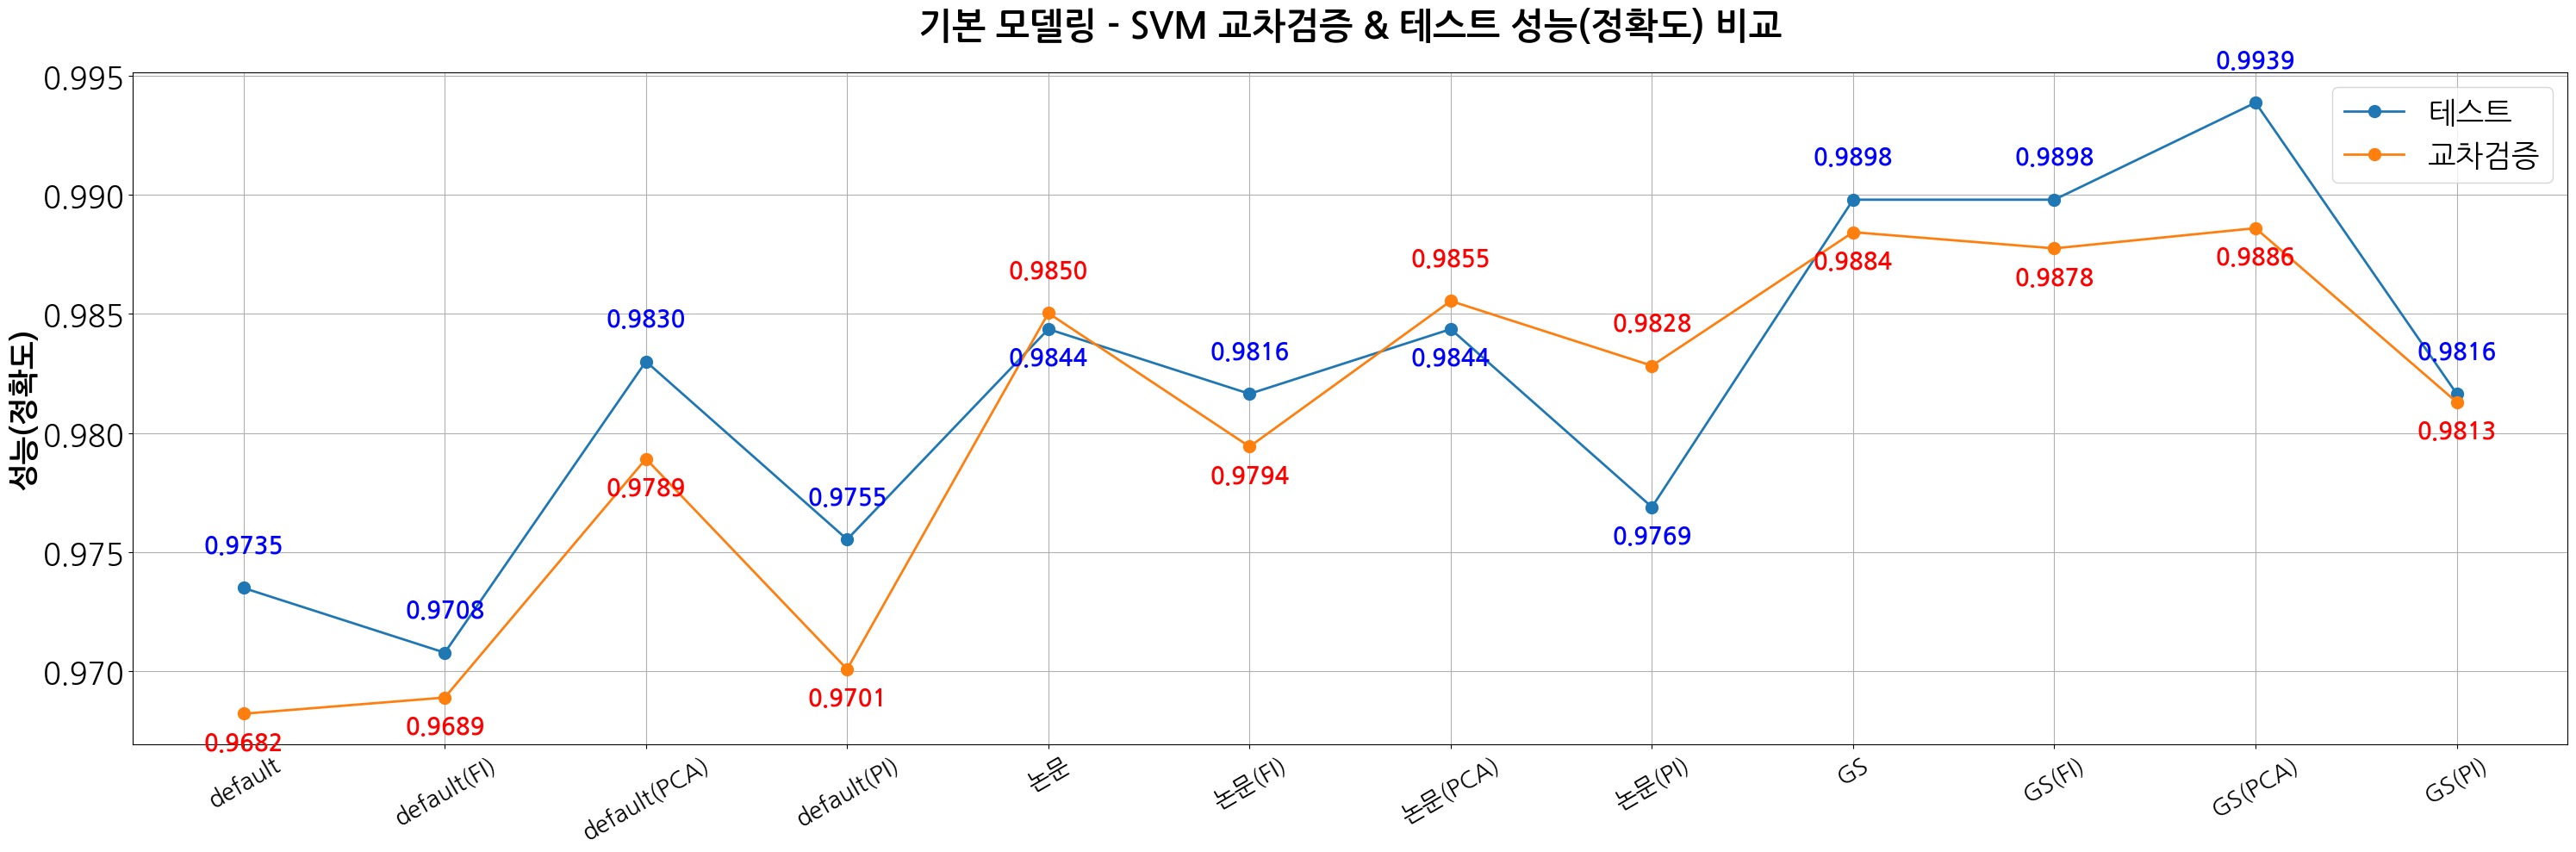

In [38]:
# x축 라벨
x_labels = ['default', 'default(FI)', 'default(PCA)', 'default(PI)',
            '논문', '논문(FI)', '논문(PCA)', '논문(PI)',
            'GS', 'GS(FI)', 'GS(PCA)', 'GS(PI)']

# LogisticRegression 테스트 및 교차검증 정확도 추출
svm_test = df.loc['SVM', [
    'default_정확도(테스트)', 'default_정확도(fi_테스트)', 'default_정확도(pca_테스트)', 'default_정확도(pi_테스트)',
    '논문_정확도(테스트)', '논문_정확도(fi_테스트)', '논문_정확도(pca_테스트)', '논문_정확도(pi_테스트)',
    'gs_정확도(테스트)', 'gs_정확도(fi_테스트)', 'gs_정확도(pca_테스트)', 'gs_정확도(pi_테스트)'
]]

svm_cv = df.loc['SVM', [
    'default_정확도(교차검증)', 'default_정확도(fi_교차검증)', 'default_정확도(pca_교차검증)', 'default_정확도(pi_교차검증)',
    '논문_정확도(교차검증)', '논문_정확도(fi_교차검증)', '논문_정확도(pca_교차검증)', '논문_정확도(pi_교차검증)',
    'gs_정확도(교차검증)', 'gs_정확도(fi_교차검증)', 'gs_정확도(pca_교차검증)', 'gs_정확도(pi_교차검증)'
]]

# 그래프 그리기
plt.figure(figsize=(30, 10))
plt.plot(x_labels, svm_test.values, marker='o', markersize=10, linewidth=2, label='테스트')
plt.plot(x_labels, svm_cv.values, marker='o', markersize=10, linewidth=2, label='교차검증')

for i, (test_val, cv_val) in enumerate(zip(svm_test.values, svm_cv.values)):
    if test_val >= cv_val:
        plt.text(i, test_val + 0.0015, f"{test_val:.4f}", ha='center', fontsize=20, color='blue', fontweight='bold')
        plt.text(i, cv_val - 0.0015, f"{cv_val:.4f}", ha='center', fontsize=20, color='red', fontweight='bold')
    else:
        plt.text(i, test_val - 0.0015, f"{test_val:.4f}", ha='center', fontsize=20, color='blue', fontweight='bold')
        plt.text(i, cv_val + 0.0015, f"{cv_val:.4f}", ha='center', fontsize=20, color='red', fontweight='bold')

# 축, 제목, 범례 설정
plt.xticks(rotation=30, fontsize=20)
plt.yticks(fontsize=25)
plt.ylabel("성능(정확도)", fontsize=25, fontweight='bold')
plt.title("기본 모델링 - SVM 교차검증 & 테스트 성능(정확도) 비교", fontsize=30, fontweight='bold', pad=30)
plt.legend(fontsize=25)
plt.grid(True)
plt.tight_layout()
plt.show()

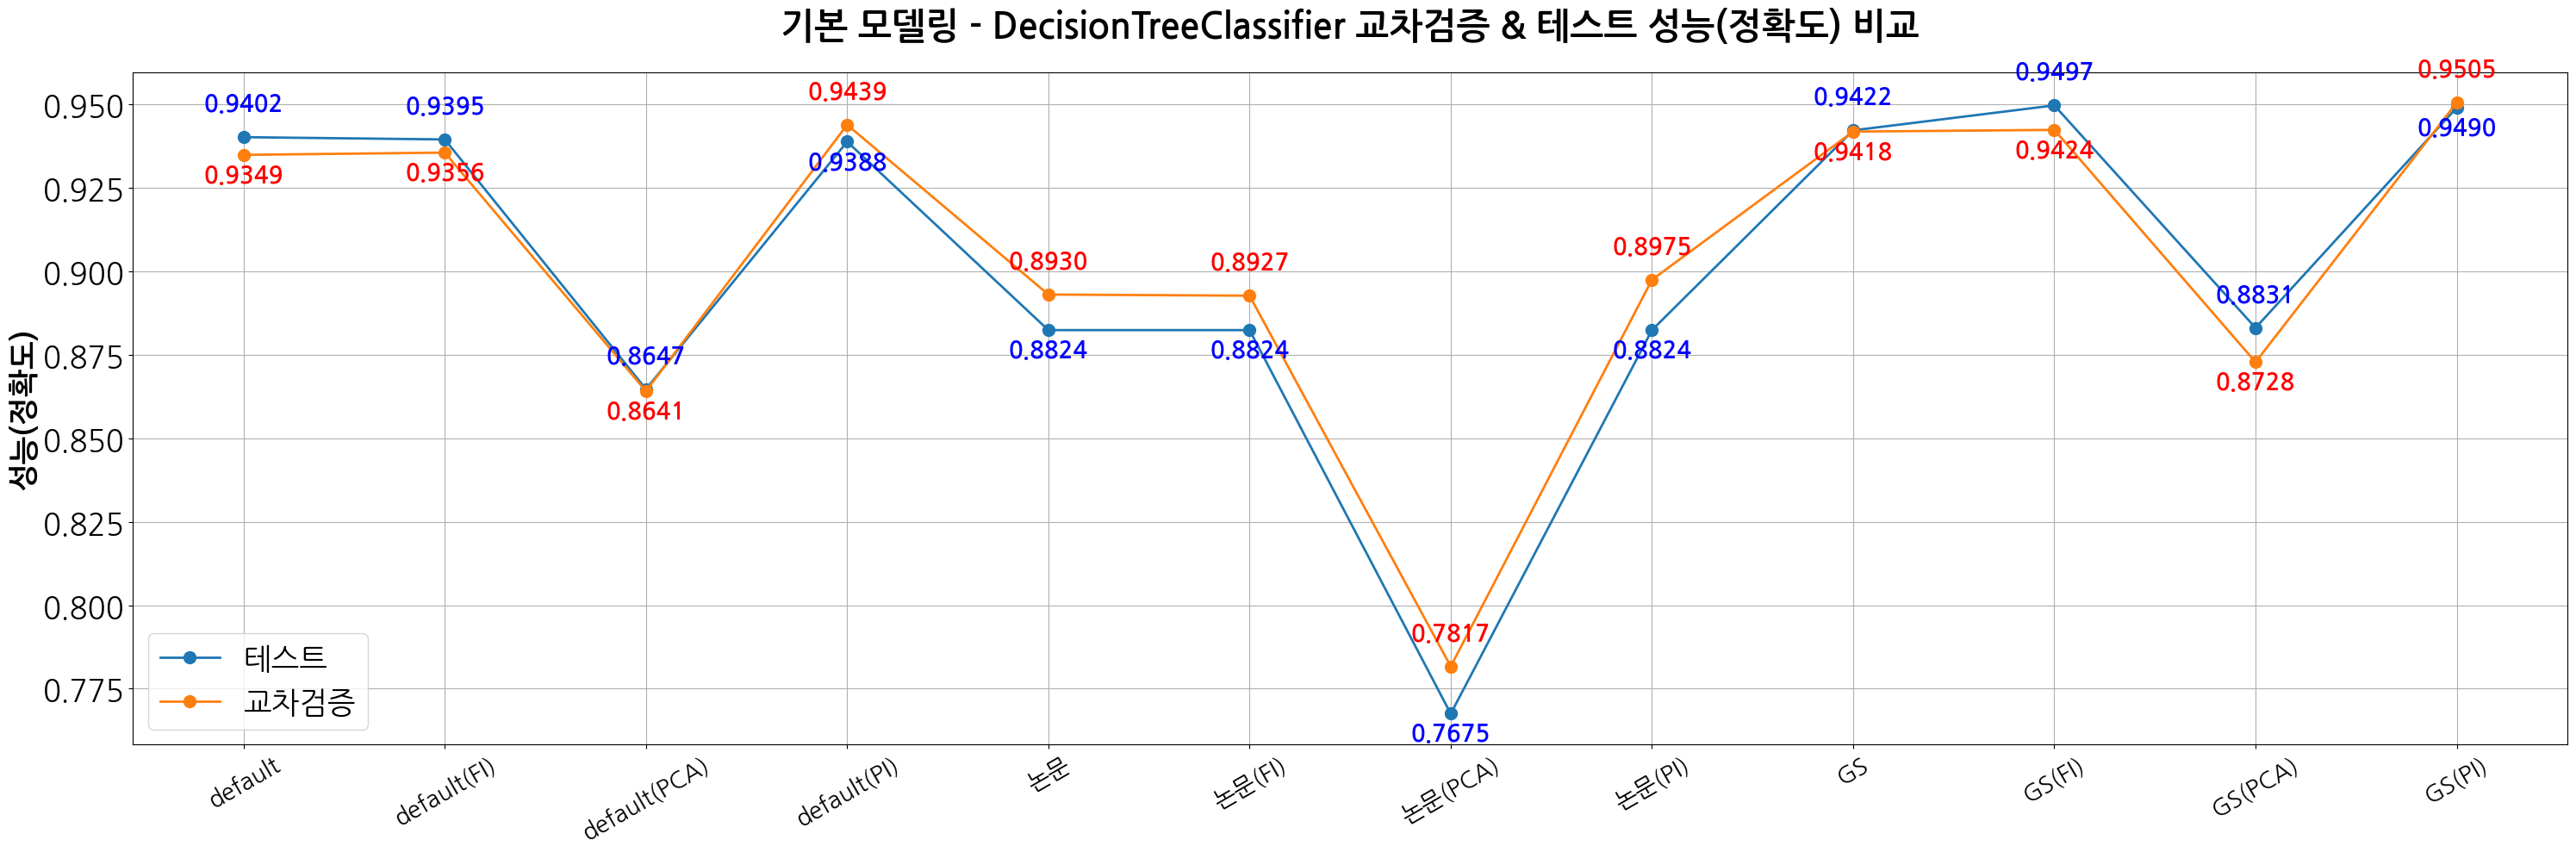

In [39]:
# x축 라벨
x_labels = ['default', 'default(FI)', 'default(PCA)', 'default(PI)',
            '논문', '논문(FI)', '논문(PCA)', '논문(PI)',
            'GS', 'GS(FI)', 'GS(PCA)', 'GS(PI)']

# LogisticRegression 테스트 및 교차검증 정확도 추출
dt_test = df.loc['DecisionTreeClassifier', [
    'default_정확도(테스트)', 'default_정확도(fi_테스트)', 'default_정확도(pca_테스트)', 'default_정확도(pi_테스트)',
    '논문_정확도(테스트)', '논문_정확도(fi_테스트)', '논문_정확도(pca_테스트)', '논문_정확도(pi_테스트)',
    'gs_정확도(테스트)', 'gs_정확도(fi_테스트)', 'gs_정확도(pca_테스트)', 'gs_정확도(pi_테스트)'
]]

dt_cv = df.loc['DecisionTreeClassifier', [
    'default_정확도(교차검증)', 'default_정확도(fi_교차검증)', 'default_정확도(pca_교차검증)', 'default_정확도(pi_교차검증)',
    '논문_정확도(교차검증)', '논문_정확도(fi_교차검증)', '논문_정확도(pca_교차검증)', '논문_정확도(pi_교차검증)',
    'gs_정확도(교차검증)', 'gs_정확도(fi_교차검증)', 'gs_정확도(pca_교차검증)', 'gs_정확도(pi_교차검증)'
]]

# 그래프 그리기
plt.figure(figsize=(30, 10))
plt.plot(x_labels, dt_test.values, marker='o', markersize=10, linewidth=2, label='테스트')
plt.plot(x_labels, dt_cv.values, marker='o', markersize=10, linewidth=2, label='교차검증')

for i, (test_val, cv_val) in enumerate(zip(dt_test.values, dt_cv.values)):
    if test_val >= cv_val:
        plt.text(i, test_val + 0.008, f"{test_val:.4f}", ha='center', fontsize=20, color='blue', fontweight='bold')
        plt.text(i, cv_val - 0.008, f"{cv_val:.4f}", ha='center', fontsize=20, color='red', fontweight='bold')
    else:
        plt.text(i, test_val - 0.008, f"{test_val:.4f}", ha='center', fontsize=20, color='blue', fontweight='bold')
        plt.text(i, cv_val + 0.008, f"{cv_val:.4f}", ha='center', fontsize=20, color='red', fontweight='bold')

# 축, 제목, 범례 설정
plt.xticks(rotation=30, fontsize=20)
plt.yticks(fontsize=25)
plt.ylabel("성능(정확도)", fontsize=25, fontweight='bold')
plt.title("기본 모델링 - DecisionTreeClassifier 교차검증 & 테스트 성능(정확도) 비교", fontsize=30, fontweight='bold', pad=30)
plt.legend(fontsize=25)
plt.grid(True)
plt.tight_layout()
plt.show()

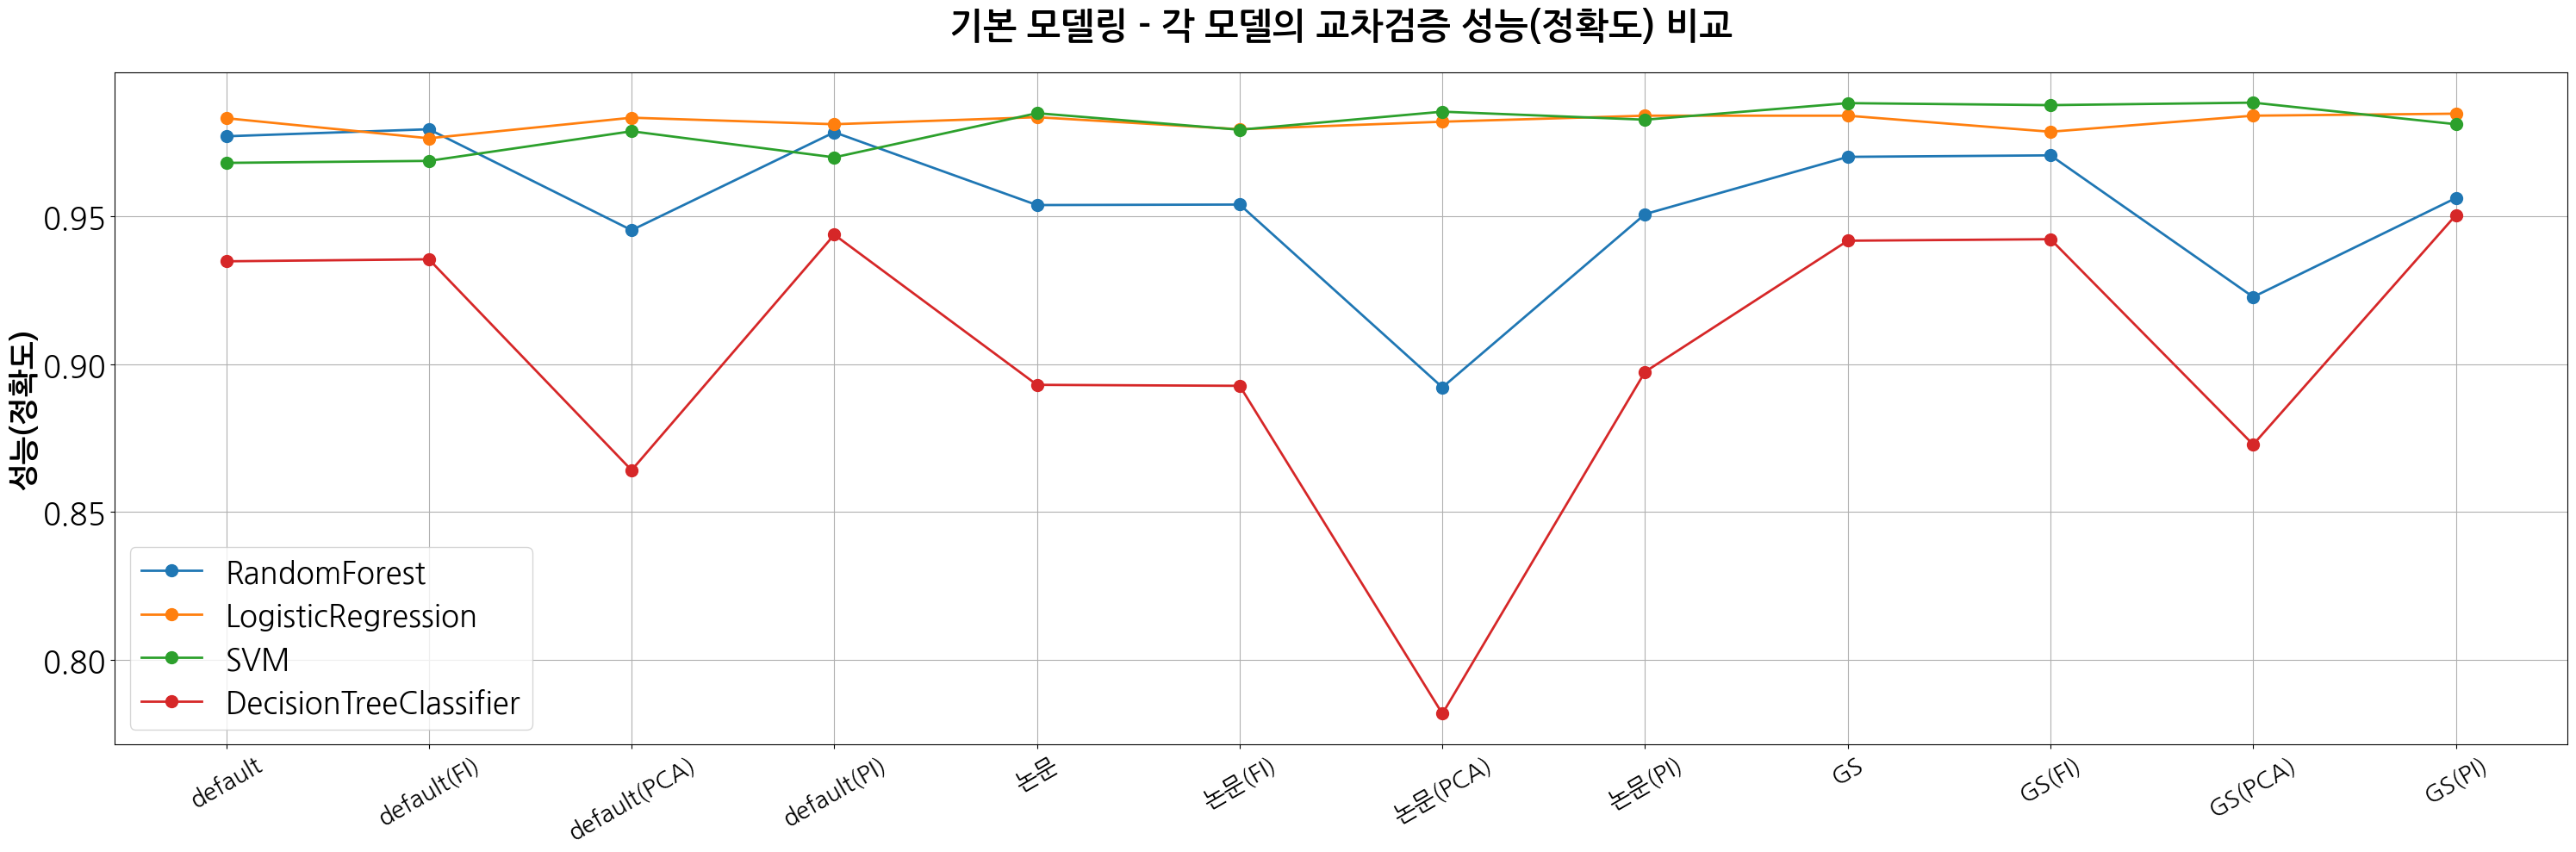

In [40]:
# x축 라벨
x_labels = ['default', 'default(FI)', 'default(PCA)', 'default(PI)',
            '논문', '논문(FI)', '논문(PCA)', '논문(PI)',
            'GS', 'GS(FI)', 'GS(PCA)', 'GS(PI)']


rf_cv = df.loc['RandomForest', [
    'default_정확도(교차검증)', 'default_정확도(fi_교차검증)', 'default_정확도(pca_교차검증)', 'default_정확도(pi_교차검증)',
    '논문_정확도(교차검증)', '논문_정확도(fi_교차검증)', '논문_정확도(pca_교차검증)', '논문_정확도(pi_교차검증)',
    'gs_정확도(교차검증)', 'gs_정확도(fi_교차검증)', 'gs_정확도(pca_교차검증)', 'gs_정확도(pi_교차검증)'
]]

lr_cv = df.loc['LogisticRegression', [
    'default_정확도(교차검증)', 'default_정확도(fi_교차검증)', 'default_정확도(pca_교차검증)', 'default_정확도(pi_교차검증)',
    '논문_정확도(교차검증)', '논문_정확도(fi_교차검증)', '논문_정확도(pca_교차검증)', '논문_정확도(pi_교차검증)',
    'gs_정확도(교차검증)', 'gs_정확도(fi_교차검증)', 'gs_정확도(pca_교차검증)', 'gs_정확도(pi_교차검증)'
]]

svm_cv = df.loc['SVM', [
    'default_정확도(교차검증)', 'default_정확도(fi_교차검증)', 'default_정확도(pca_교차검증)', 'default_정확도(pi_교차검증)',
    '논문_정확도(교차검증)', '논문_정확도(fi_교차검증)', '논문_정확도(pca_교차검증)', '논문_정확도(pi_교차검증)',
    'gs_정확도(교차검증)', 'gs_정확도(fi_교차검증)', 'gs_정확도(pca_교차검증)', 'gs_정확도(pi_교차검증)'
]]

dt_cv = df.loc['DecisionTreeClassifier', [
    'default_정확도(교차검증)', 'default_정확도(fi_교차검증)', 'default_정확도(pca_교차검증)', 'default_정확도(pi_교차검증)',
    '논문_정확도(교차검증)', '논문_정확도(fi_교차검증)', '논문_정확도(pca_교차검증)', '논문_정확도(pi_교차검증)',
    'gs_정확도(교차검증)', 'gs_정확도(fi_교차검증)', 'gs_정확도(pca_교차검증)', 'gs_정확도(pi_교차검증)'
]]

# 그래프 그리기
plt.figure(figsize=(30, 10))
plt.plot(x_labels, rf_cv.values, marker='o', markersize=10, linewidth=2, label='RandomForest')
plt.plot(x_labels, lr_cv.values, marker='o', markersize=10, linewidth=2, label='LogisticRegression')
plt.plot(x_labels, svm_cv.values, marker='o', markersize=10, linewidth=2, label='SVM')
plt.plot(x_labels, dt_cv.values, marker='o', markersize=10, linewidth=2, label='DecisionTreeClassifier')

# 축, 제목, 범례 설정
plt.xticks(rotation=30, fontsize=20)
plt.yticks(fontsize=25)
plt.ylabel("성능(정확도)", fontsize=25, fontweight='bold')
plt.title("기본 모델링 - 각 모델의 교차검증 성능(정확도) 비교", fontsize=30, fontweight='bold', pad=30)
plt.legend(fontsize=25)
plt.grid(True)
plt.tight_layout()
plt.show()

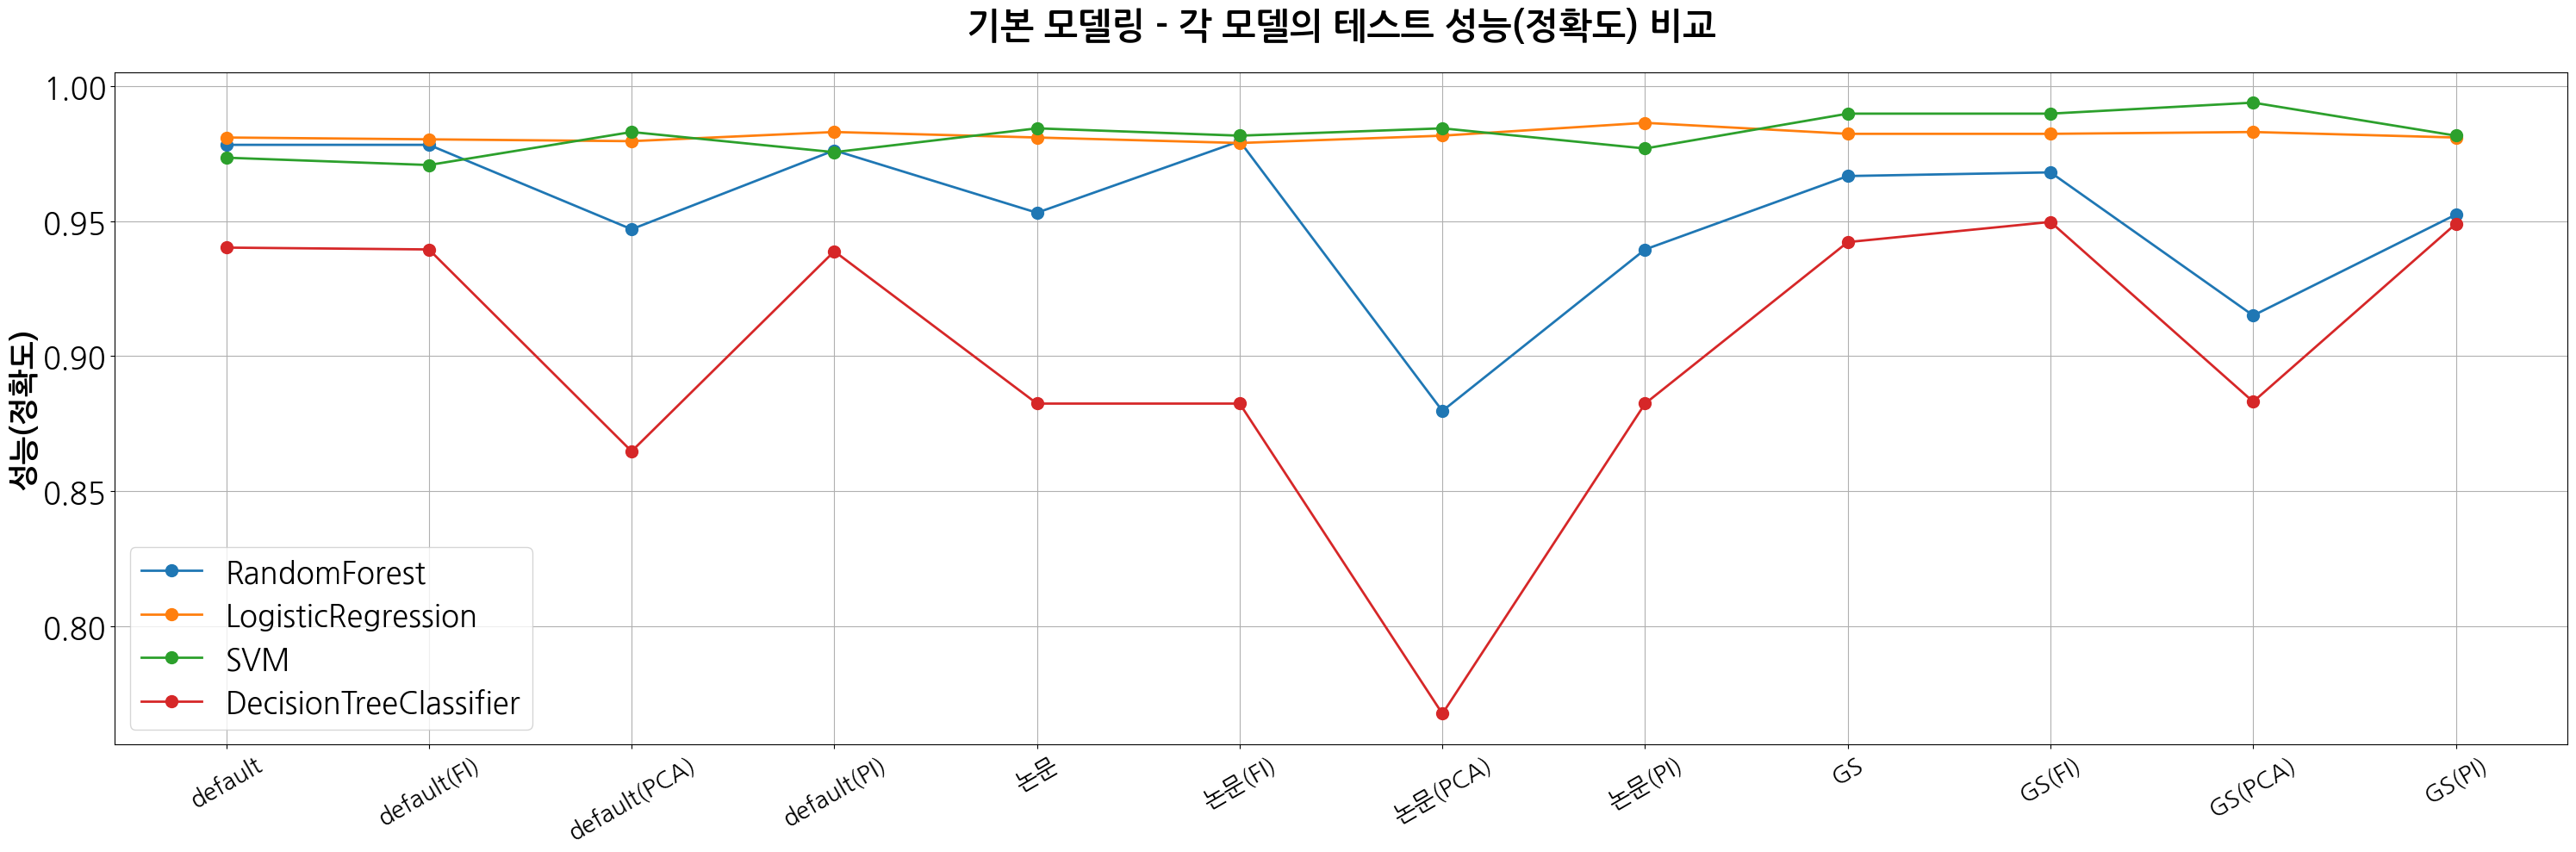

In [41]:
# x축 라벨
x_labels = ['default', 'default(FI)', 'default(PCA)', 'default(PI)',
            '논문', '논문(FI)', '논문(PCA)', '논문(PI)',
            'GS', 'GS(FI)', 'GS(PCA)', 'GS(PI)']

# RandomForest 테스트 및 교차검증 정확도 추출
rf_test = df.loc['RandomForest', [
    'default_정확도(테스트)', 'default_정확도(fi_테스트)', 'default_정확도(pca_테스트)', 'default_정확도(pi_테스트)',
    '논문_정확도(테스트)', '논문_정확도(fi_테스트)', '논문_정확도(pca_테스트)', '논문_정확도(pi_테스트)',
    'gs_정확도(테스트)', 'gs_정확도(fi_테스트)', 'gs_정확도(pca_테스트)', 'gs_정확도(pi_테스트)'
]]

lr_test = df.loc['LogisticRegression', [
    'default_정확도(테스트)', 'default_정확도(fi_테스트)', 'default_정확도(pca_테스트)', 'default_정확도(pi_테스트)',
    '논문_정확도(테스트)', '논문_정확도(fi_테스트)', '논문_정확도(pca_테스트)', '논문_정확도(pi_테스트)',
    'gs_정확도(테스트)', 'gs_정확도(fi_테스트)', 'gs_정확도(pca_테스트)', 'gs_정확도(pi_테스트)'
]]

svm_test = df.loc['SVM', [
    'default_정확도(테스트)', 'default_정확도(fi_테스트)', 'default_정확도(pca_테스트)', 'default_정확도(pi_테스트)',
    '논문_정확도(테스트)', '논문_정확도(fi_테스트)', '논문_정확도(pca_테스트)', '논문_정확도(pi_테스트)',
    'gs_정확도(테스트)', 'gs_정확도(fi_테스트)', 'gs_정확도(pca_테스트)', 'gs_정확도(pi_테스트)'
]]

dt_test = df.loc['DecisionTreeClassifier', [
    'default_정확도(테스트)', 'default_정확도(fi_테스트)', 'default_정확도(pca_테스트)', 'default_정확도(pi_테스트)',
    '논문_정확도(테스트)', '논문_정확도(fi_테스트)', '논문_정확도(pca_테스트)', '논문_정확도(pi_테스트)',
    'gs_정확도(테스트)', 'gs_정확도(fi_테스트)', 'gs_정확도(pca_테스트)', 'gs_정확도(pi_테스트)'
]]

# 그래프 그리기
plt.figure(figsize=(30, 10))
plt.plot(x_labels, rf_test.values, marker='o', markersize=10, linewidth=2, label='RandomForest')
plt.plot(x_labels, lr_test.values, marker='o', markersize=10, linewidth=2, label='LogisticRegression')
plt.plot(x_labels, svm_test.values, marker='o', markersize=10, linewidth=2, label='SVM')
plt.plot(x_labels, dt_test.values, marker='o', markersize=10, linewidth=2, label='DecisionTreeClassifier')

# # 각 지점에 정확도 주석 달기 (겹치지 않게 위/아래로)
# for i, (test_val, cv_val) in enumerate(zip(rf_test.values, rf_cv.values)):
#     plt.text(i, test_val + 0.005, f"{test_val:.4f}", ha='center', fontsize=20, color='blue')
#     plt.text(i, cv_val - 0.005, f"{cv_val:.4f}", ha='center', fontsize=20, color='red')

# 축, 제목, 범례 설정
plt.xticks(rotation=30, fontsize=20)
plt.yticks(fontsize=25)
plt.ylabel("성능(정확도)", fontsize=25, fontweight='bold')
plt.title("기본 모델링 - 각 모델의 테스트 성능(정확도) 비교", fontsize=30, fontweight='bold', pad=30)
plt.legend(fontsize=25)
plt.grid(True)
plt.tight_layout()
plt.show()